# HPP results per D

Plots of one HPP benchmark run (`experiments/hpp_comparison/run_benchmark_script_1cap_2obs.py`), continuous vs discrete
collision checking, against D (how far the cap turns, in rad). One dot per run, short dark line = median.
Search time, nodes and path lengths exist only for successful runs: check the success rate first. Failed runs hit the
1800 s timeout and are drawn as × on the search-time plot.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# The run to plot: the newest folder in 1cap_2obs/ (or set RUN_DIR by hand).
RUN_DIR = sorted(p for p in Path("1cap_2obs").iterdir() if p.is_dir())[-1]
print(RUN_DIR)

CHECKS = ["continuous", "discrete"]
COLORS = {"continuous": "#2a78d6", "discrete": "#eb6834"}   # colour-blind-safe pair
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e6e3"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED})

1cap_2obs/2026-11-19_14-19-13 (with floor)


In [2]:
# One row per run, from the JSON file each (collision check, D) call wrote.
runs = []
for f in sorted(RUN_DIR.glob("*_D*.json")):
    result = json.loads(f.read_text())
    for r in result["runs"]:
        runs.append(dict(check=result["collision_check"], D=float(result["D"]), **r))
TIMEOUT = result["timeout_search"]
summary = json.loads((RUN_DIR / "summary.json").read_text())   # also lists the D values that were not run
DS = sorted({r["D"] for r in runs})   # D values with at least one run
skipped = sorted({float(s["D"]) for s in summary} - set(DS))
print(f"{len(runs)} runs, D values {DS}, timeout {TIMEOUT} s")
print(f"not run for either check (a smaller D already had no success): {skipped}")

108 runs, D values [0.5, 1.0, 2.0, 3.0], timeout 1800 s
not run for either check (a smaller D already had no success): [4.0, 5.0, 6.0]


In [3]:
def runs_of(check, D):
    return [r for r in runs if r["check"] == check and r["D"] == D]


def x_of(i, check):
    # The two collision checks side by side at each D.
    return i + (-0.17 if check == "continuous" else 0.17)


def finish(ax, title, ylabel, handles):
    ax.set_xticks(range(len(DS)), [f"{D:g}" for D in DS])
    ax.set_xlim(-0.5, len(DS) - 0.5)
    ax.set_xlabel("D: cap turn (rad)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    plt.tight_layout()
    plt.show()


def dot_plot(metric, title, ylabel, log=False):
    """One dot per successful run, a median line, per D and collision check."""
    fig, ax = plt.subplots(figsize=(8.8 if metric == "search_time" else 7.5, 3.4))   # wider: minute labels
    rng = np.random.default_rng(0)   # fixed jitter: the plot does not change between runs
    for check in CHECKS:
        for i, D in enumerate(DS):
            mine = runs_of(check, D)
            ok = [r[metric] for r in mine if r["success"]]
            x = x_of(i, check)
            if ok:
                ax.scatter(x + rng.uniform(-0.06, 0.06, len(ok)), ok, s=28, color=COLORS[check], alpha=0.85,
                           edgecolors="white", linewidths=0.8, zorder=3)
                ax.hlines(np.median(ok), x - 0.11, x + 0.11, color=INK, linewidth=2, zorder=4)
            n_failed = len(mine) - len(ok)
            if metric == "search_time" and n_failed:
                ax.scatter(x + rng.uniform(-0.06, 0.06, n_failed), [TIMEOUT] * n_failed, marker="x", s=36,
                           color=COLORS[check], linewidths=1.5, zorder=3)
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=COLORS[c], label=c) for c in CHECKS]
    handles.append(plt.Line2D([], [], color=INK, linewidth=2, label="median"))
    if metric == "search_time":
        ax.axhline(TIMEOUT, color=MUTED, linewidth=1, linestyle="--", zorder=1)
        handles.append(plt.Line2D([], [], marker="x", linestyle="", color=MUTED, label=f"failed ({TIMEOUT:g} s = {TIMEOUT / 60:g} min timeout)"))
    if log:
        ax.set_yscale("log")
    if metric == "search_time":   # tick labels in seconds, and from 10 s also in minutes
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda s, _: f"{s:g} s" + (f" ≈ {s / 60:.2g} min" if s >= 10 else "")))
    finish(ax, title, ylabel, handles)

## Success rate

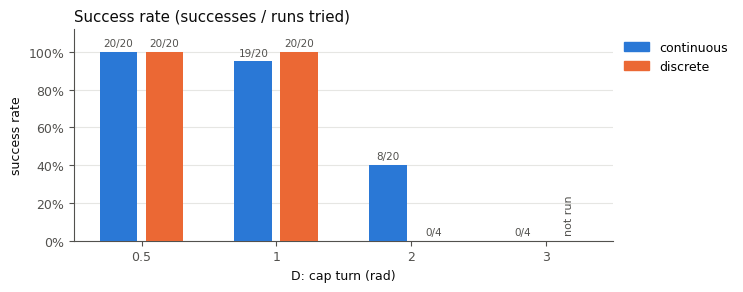

not run: a smaller D already had no success. 0/4: the first runs all failed, so the rest was skipped.


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
for check in CHECKS:
    for i, D in enumerate(DS):
        mine, x = runs_of(check, D), x_of(i, check)
        if not mine:
            ax.text(x, 0.03, "not run", rotation=90, ha="center", va="bottom", color=MUTED, fontsize=8)
            continue
        n_ok = sum(r["success"] for r in mine)
        ax.bar(x, n_ok / len(mine), width=0.28, color=COLORS[check], zorder=3)
        ax.text(x, n_ok / len(mine) + 0.02, f"{n_ok}/{len(mine)}", ha="center", va="bottom", color=MUTED, fontsize=7.5)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[c], label=c) for c in CHECKS]
finish(ax, "Success rate (successes / runs tried)", "success rate", handles)
print("not run: a smaller D already had no success. 0/4: the first runs all failed, so the rest was skipped.")

## Search time, nodes, path length

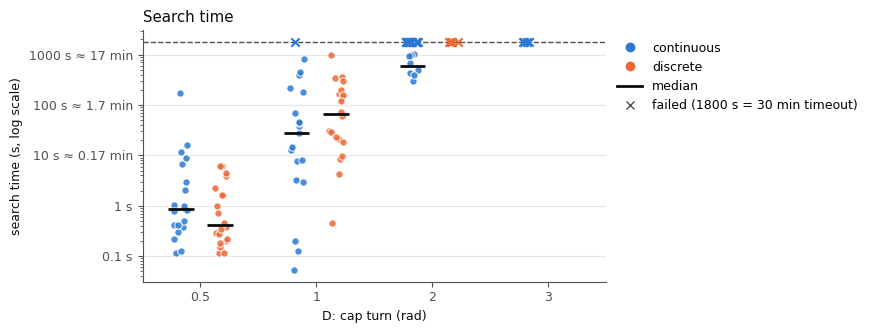

In [ ]:
dot_plot("search_time", "Search time", "search time (s, log scale)", log=True)

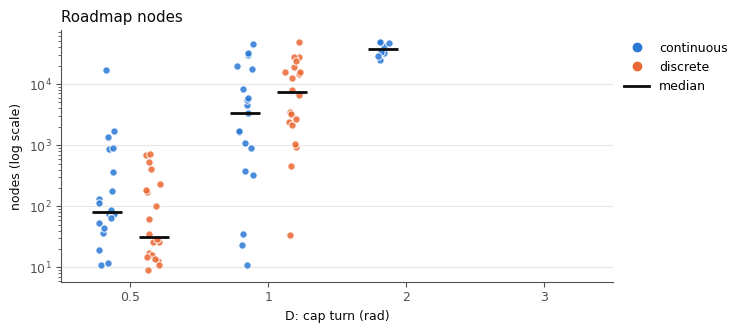

In [ ]:
dot_plot("node_number", "Roadmap nodes", "nodes (log scale)", log=True)

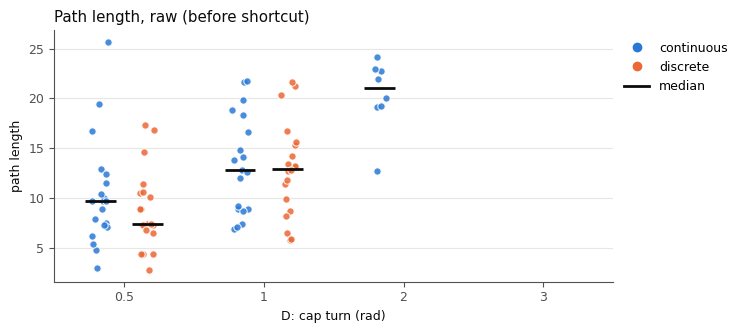

In [ ]:
dot_plot("pathlength_raw", "Path length, raw (before shortcut)", "path length")

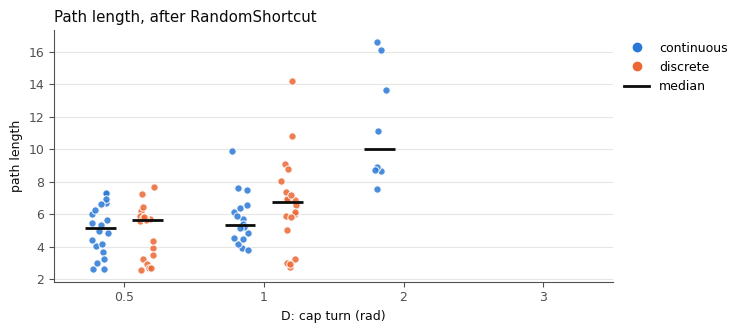

In [ ]:
dot_plot("pathlength_shortcut", "Path length, after RandomShortcut", "path length")

## Raw vs shortcut path length

Each thin line is one run: its raw path length (hollow dot) and its length after RandomShortcut (filled dot).

continuous D=0.5: median   9.7 ->  5.2, a run gets 43% shorter (median over runs)
continuous D=1: median  12.8 ->  5.4, a run gets 53% shorter (median over runs)
continuous D=2: median  21.0 -> 10.0, a run gets 41% shorter (median over runs)
discrete   D=0.5: median   7.4 ->  5.7, a run gets 42% shorter (median over runs)
discrete   D=1: median  12.9 ->  6.8, a run gets 49% shorter (median over runs)


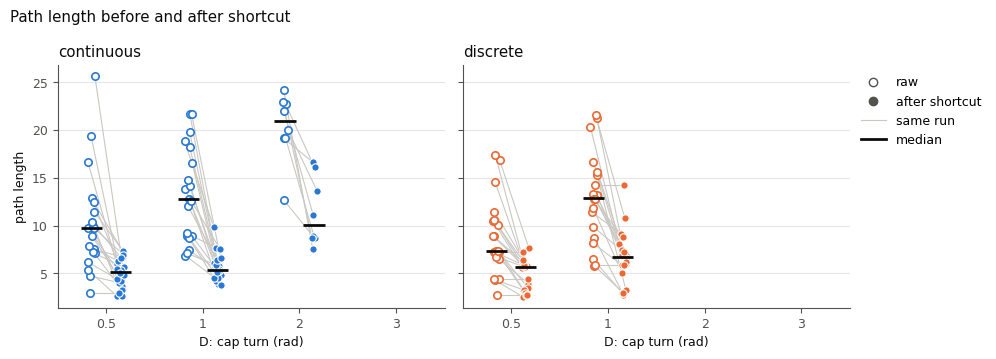

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
rng = np.random.default_rng(0)
for ax, check in zip(axes, CHECKS):
    for i, D in enumerate(DS):
        ok = [r for r in runs_of(check, D) if r["success"]]
        if not ok:
            continue
        raw = np.array([r["pathlength_raw"] for r in ok])
        short = np.array([r["pathlength_shortcut"] for r in ok])
        jitter = rng.uniform(-0.04, 0.04, len(ok))   # same jitter at both ends, so each line stays one run
        for j, a, b in zip(jitter, raw, short):
            ax.plot([i - 0.15 + j, i + 0.15 + j], [a, b], color="#c9c8c2", linewidth=0.8, zorder=1)
        ax.scatter(i - 0.15 + jitter, raw, s=28, facecolors="white", edgecolors=COLORS[check], linewidths=1.2, zorder=3)
        ax.scatter(i + 0.15 + jitter, short, s=28, color=COLORS[check], edgecolors="white", linewidths=0.8, zorder=3)
        ax.hlines(np.median(raw), i - 0.26, i - 0.04, color=INK, linewidth=2, zorder=4)
        ax.hlines(np.median(short), i + 0.04, i + 0.26, color=INK, linewidth=2, zorder=4)
        print(f"{check:10s} D={D:g}: median {np.median(raw):5.1f} -> {np.median(short):4.1f}, "
              f"a run gets {100 * (1 - np.median(short / raw)):.0f}% shorter (median over runs)")
    ax.set_xticks(range(len(DS)), [f"{D:g}" for D in DS])
    ax.set_xlim(-0.5, len(DS) - 0.5)
    ax.set_xlabel("D: cap turn (rad)")
    ax.set_title(check, loc="left", color=INK)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("path length")
handles = [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=MUTED, label="raw"),
           plt.Line2D([], [], marker="o", linestyle="", color=MUTED, label="after shortcut"),
           plt.Line2D([], [], color="#c9c8c2", linewidth=0.8, label="same run"),
           plt.Line2D([], [], color=INK, linewidth=2, label="median")]
axes[1].legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.suptitle("Path length before and after shortcut", x=0.01, ha="left", color=INK)
plt.tight_layout()
plt.show()

## Mean, median and std (successful runs only)

In [ ]:
METRICS = {"search_time": "search time (s)", "node_number": "nodes", "pathlength_raw": "path length, raw",
           "pathlength_shortcut": "path length, shortcut"}
for metric, name in METRICS.items():
    lines = [f"**{name}**", "", "| check | D | successes | mean | median | std |", "|---|---|---|---|---|---|"]
    for check in CHECKS:
        for D in DS:
            mine = runs_of(check, D)
            ok = np.array([r[metric] for r in mine if r["success"]], dtype=float)
            if not mine:
                lines.append(f"| {check} | {D:g} | not run | | | |")
            elif len(ok) == 0:
                lines.append(f"| {check} | {D:g} | 0/{len(mine)} | | | |")
            else:
                lines.append(f"| {check} | {D:g} | {len(ok)}/{len(mine)} | {ok.mean():.3g} | {np.median(ok):.3g} | {ok.std():.3g} |")
    display(Markdown("\n".join(lines)))

**search time (s)**

| check | D | successes | mean | median | std |
|---|---|---|---|---|---|
| continuous | 0.5 | 20/20 | 11.4 | 0.847 | 37.2 |
| continuous | 1 | 19/20 | 123 | 27.3 | 208 |
| continuous | 2 | 8/20 | 654 | 593 | 271 |
| continuous | 3 | 0/4 | | | |
| discrete | 0.5 | 20/20 | 1.54 | 0.414 | 1.97 |
| discrete | 1 | 20/20 | 152 | 66 | 218 |
| discrete | 2 | 0/4 | | | |
| discrete | 3 | not run | | | |

**nodes**

| check | D | successes | mean | median | std |
|---|---|---|---|---|---|
| continuous | 0.5 | 20/20 | 1.15e+03 | 81.5 | 3.63e+03 |
| continuous | 1 | 19/20 | 9.32e+03 | 3.33e+03 | 1.28e+04 |
| continuous | 2 | 8/20 | 3.8e+04 | 3.75e+04 | 8.92e+03 |
| continuous | 3 | 0/4 | | | |
| discrete | 0.5 | 20/20 | 166 | 32 | 227 |
| discrete | 1 | 20/20 | 1.18e+04 | 7.3e+03 | 1.24e+04 |
| discrete | 2 | 0/4 | | | |
| discrete | 3 | not run | | | |

**path length, raw**

| check | D | successes | mean | median | std |
|---|---|---|---|---|---|
| continuous | 0.5 | 20/20 | 10.3 | 9.71 | 5.17 |
| continuous | 1 | 19/20 | 13.4 | 12.8 | 4.84 |
| continuous | 2 | 8/20 | 20.4 | 21 | 3.37 |
| continuous | 3 | 0/4 | | | |
| discrete | 0.5 | 20/20 | 8.73 | 7.37 | 3.89 |
| discrete | 1 | 20/20 | 12.9 | 12.9 | 4.6 |
| discrete | 2 | 0/4 | | | |
| discrete | 3 | not run | | | |

**path length, shortcut**

| check | D | successes | mean | median | std |
|---|---|---|---|---|---|
| continuous | 0.5 | 20/20 | 5.07 | 5.17 | 1.51 |
| continuous | 1 | 19/20 | 5.69 | 5.37 | 1.44 |
| continuous | 2 | 8/20 | 11.4 | 10 | 3.35 |
| continuous | 3 | 0/4 | | | |
| discrete | 0.5 | 20/20 | 4.99 | 5.69 | 1.55 |
| discrete | 1 | 20/20 | 6.69 | 6.75 | 2.71 |
| discrete | 2 | 0/4 | | | |
| discrete | 3 | not run | | | |